# Final project: water retention curves of tropical soils

Scientific Computing (MAPC24). Santiago Cano Molina.

This notebook is the report of the project. The code is in `src/` and it is run with `python main.py`. Here I only read the tables and figures that it saves.

## Context

The soil holds water with a force called matric potential, psi. The relation between psi and the volumetric water content, theta, is the soil water retention curve. In my thesis I want to estimate psi with a low-cost sensor and machine learning, as an alternative to tensiometers. The sensor is not built yet, so I use a public database of measured curves (Gupta et al., 2022).

The van Genuchten (1980) model describes a curve with four parameters: alpha, n, theta_r and theta_s. I describe each curve with 13 numbers (features) in three domains: retention level, curve shape and van Genuchten parameters. The question is which features change with the soil texture (coarse, medium and fine) and how well the three groups can be separated. In the thesis the texture will be an input, here I use it only as a label.

## Methodology

The project has three modules:

1. `preprocessing`: reads the file, cleans it, keeps the tropical curves with a valid texture and with enough points.
2. `analysis`: van Genuchten fit, extraction of features (three classes with the same method), statistics by group, Fisher ratio and AUC, and a nearest centroid classifier.
3. `visualization`: the figures.

The classifier is simple on purpose: the goal is to measure how separable the groups are. The training and test sets are split by site (`profile_id`), because the curves of one site are almost equal.

In [1]:
import os
import sys

sys.path.append(os.path.abspath(os.path.join("..", "..")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image

from src.config import GROUPS, COLORS
from src.preprocessing.optimized import build_curve_data_groupby
from src.visualization import plots

processed = os.path.join("..", "..", "data", "processed")
tables = os.path.join("..", "..", "results", "tables")
figures = os.path.join("..", "..", "results", "figures")
usable = pd.read_csv(os.path.join(processed, "usable_curves.csv"), index_col="layer_id")
points_table = pd.read_csv(os.path.join(processed, "selected_points.csv"))
dataset = pd.read_csv(os.path.join(processed, "features.csv"), index_col="layer_id")
curve_data = build_curve_data_groupby(points_table)

## Data and cleaning

In [2]:
steps = pd.read_csv(os.path.join(processed, "cleaning_steps.csv"))
steps

,step,rows,curves
0,raw file,136989,15259
1,without duplicates,132447,15259
2,good quality fits,112708,11705
3,without missing values,112703,11705
4,psi <= 100000 m,112652,11705
5,physical range,112652,11705
6,tropical climate,10322,1122


In [3]:
print("usable curves:", len(usable), "| points:", len(points_table), "| sites:", usable["profile_id"].nunique(),
      "| references:", usable["reference"].nunique())
print(usable["texture_group"].value_counts()[GROUPS])

usable curves: 940 | points: 9053 | sites: 270 | references: 8
texture_group
coarse    538
medium    170
fine      232
Name: count, dtype: int64


After the filters there are 940 usable curves from 270 sites and 8 references: 538 coarse, 170 medium and 232 fine. The curves with a rise of theta larger than 0.05 are marked but not removed, because 0.05 is a value that I chose.

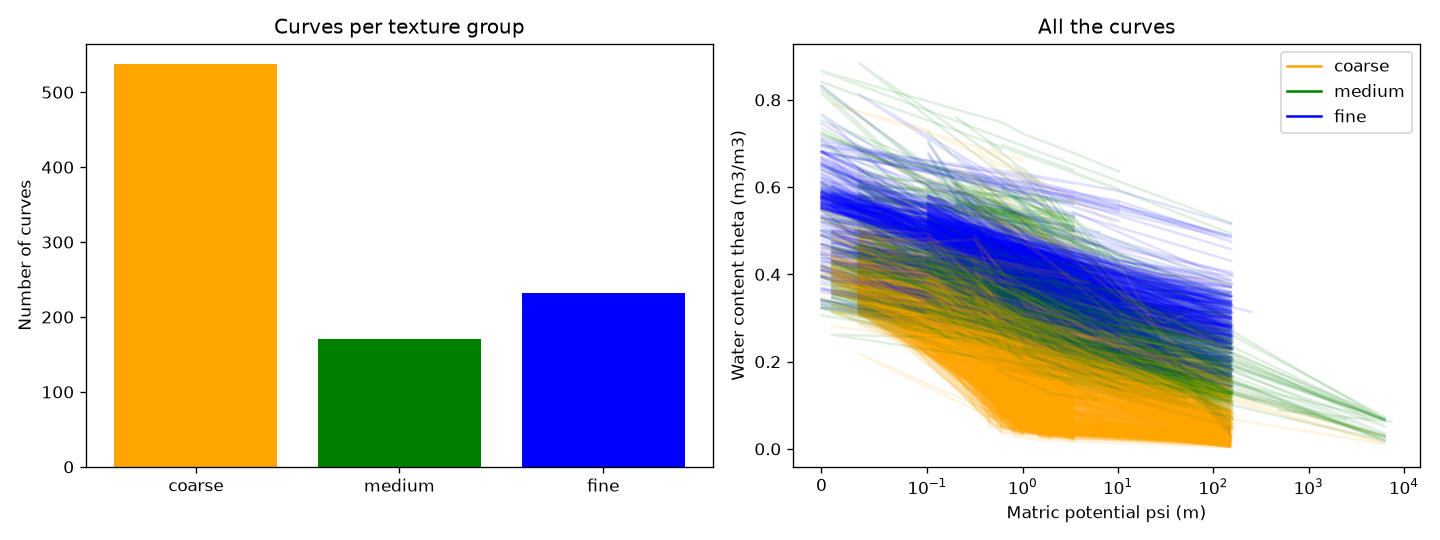

In [4]:
Image(filename=os.path.join(figures, "curves_by_group.png"))

## Features by texture group

In [5]:
features = list(dataset.columns[:13])
medians = pd.read_csv(os.path.join(tables, "summary_median.csv"), index_col=0)
medians.round(3)

,coarse,medium,fine
theta_1m,0.138,0.330,0.389
theta_3p3m,0.096,0.298,0.345
theta_10m,0.088,0.283,0.318
theta_33m,0.080,0.259,0.306
theta_100m,0.062,0.212,0.291
area_theta_logpsi,0.183,0.558,0.658
max_abs_slope,0.104,0.150,0.122
log_psi_at_max_slope,0.250,1.650,0.740
mean_abs_slope_dry,0.022,0.048,0.022
log10_alpha,0.416,0.666,0.921


The medians follow the physics. The water content at 100 m grows from coarse to fine soils, and the parameter n of the van Genuchten model is bigger for coarse soils (steeper curves). The next figures show the density of each feature in each group.

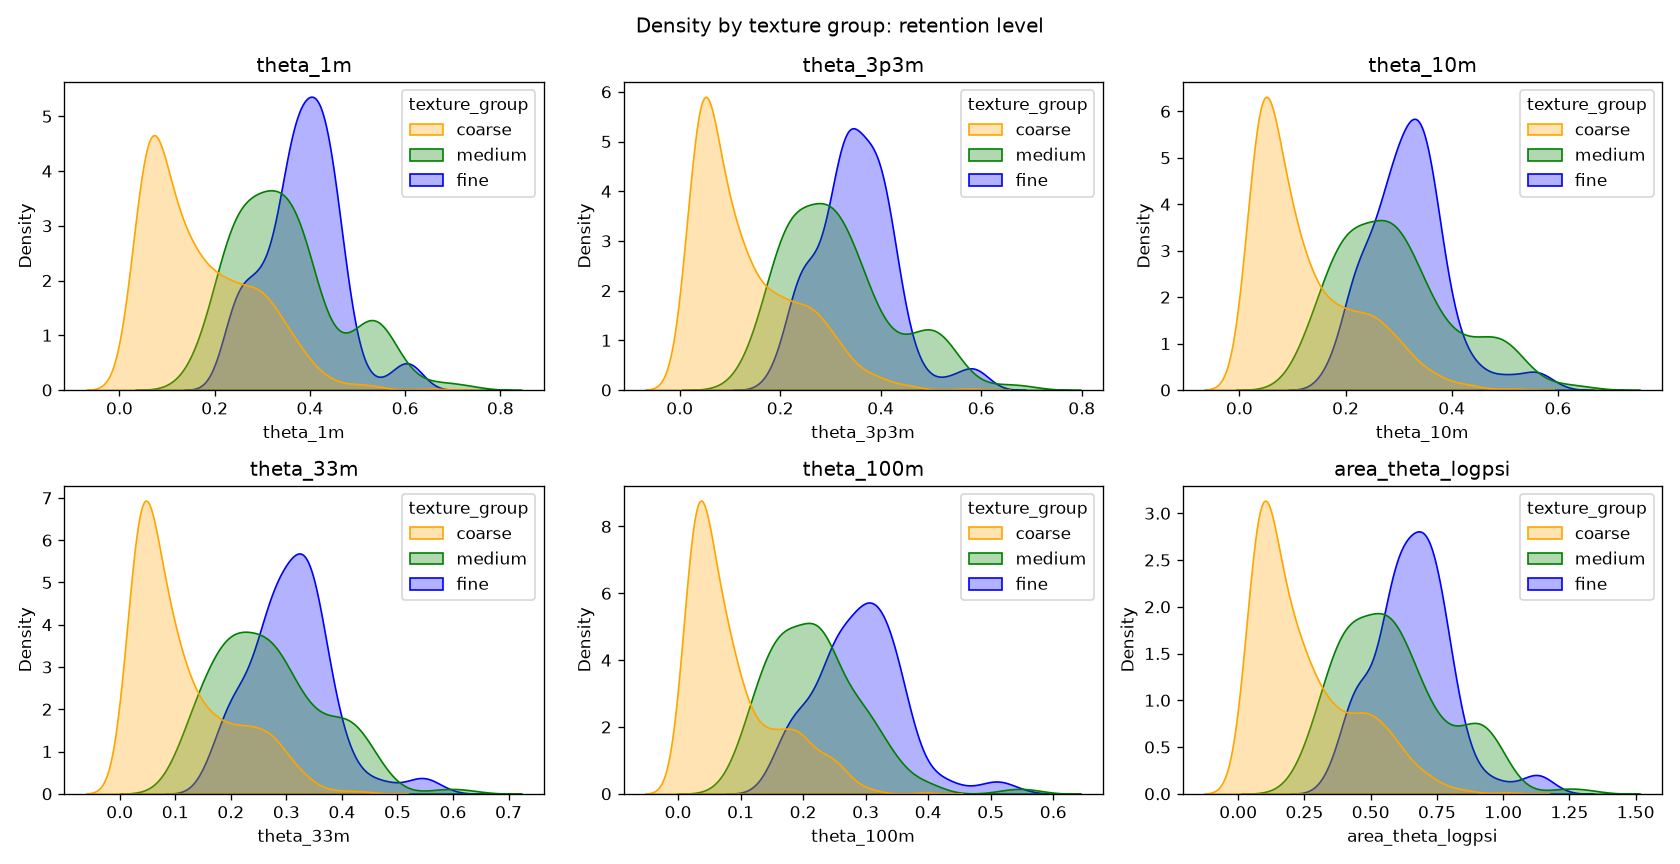

In [6]:
Image(filename=os.path.join(figures, "density_retention_level.png"))

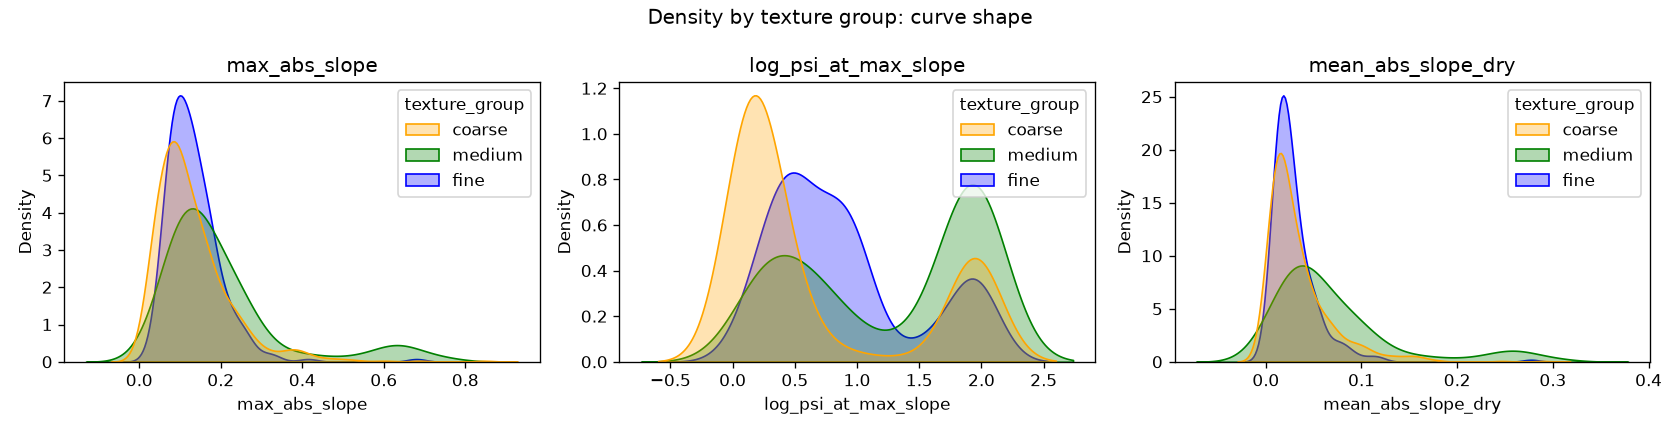

In [7]:
Image(filename=os.path.join(figures, "density_curve_shape.png"))

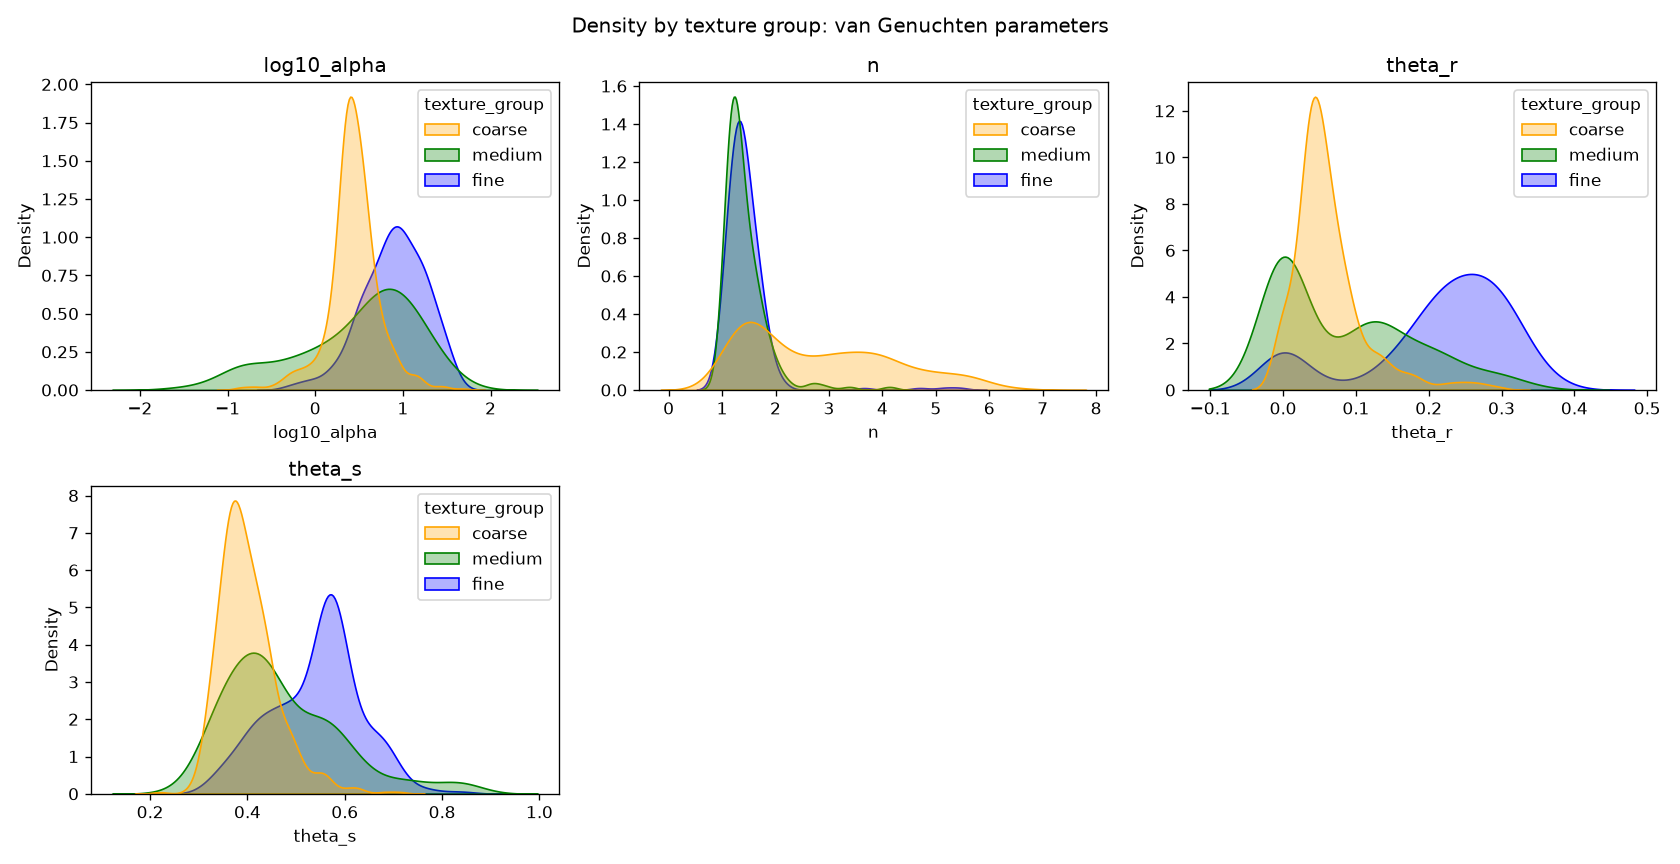

In [8]:
Image(filename=os.path.join(figures, "density_van_Genuchten_parameters.png"))

In the retention level domain the coarse group has its own peak at low water content, and medium and fine overlap. In the shape domain the three groups overlap strongly. In the van Genuchten domain the coarse group has a long tail of high values of n, medium and fine have almost the same n, and theta_r and theta_s separate the fine group better.

In [9]:
outliers = pd.read_csv(os.path.join(tables, "outliers.csv"), index_col=0)
outliers.round(1)

,outliers,share (%)
theta_1m,16,1.7
theta_3p3m,15,1.6
theta_10m,17,1.8
theta_33m,16,1.7
theta_100m,24,2.6
area_theta_logpsi,14,1.5
max_abs_slope,48,5.1
log_psi_at_max_slope,38,4.0
mean_abs_slope_dry,73,7.8
log10_alpha,59,6.3


With the 1.5 IQR rule inside each group, between 1.5 % and 7.8 % of the curves are outliers in each feature. They are real curves, so I did not remove them.

## Statistical tests and separability

In [10]:
tests = pd.read_csv(os.path.join(tables, "group_tests.csv"), index_col=0)
print("Bonferroni alpha:", round(0.05 / len(features), 5))
print(tests["test used"].value_counts().to_dict())
print("significant features:", int(tests["significant"].sum()), "of", len(tests))
tests[["min Shapiro p", "test used", "statistic", "p-value"]]

Bonferroni alpha: 0.00385
{'Kruskal-Wallis': 13}
significant features: 13 of 13


,min Shapiro p,test used,statistic,p-value
theta_1m,2.196448e-17,Kruskal-Wallis,464.460785,1.391945e-101
theta_3p3m,3.415991e-20,Kruskal-Wallis,503.752830,4.087547e-110
theta_10m,7.171552e-21,Kruskal-Wallis,469.976478,8.828856e-103
theta_33m,3.725104e-21,Kruskal-Wallis,487.019037,1.758571e-106
theta_100m,8.182613e-22,Kruskal-Wallis,558.273547,5.921606e-122
area_theta_logpsi,3.073331e-20,Kruskal-Wallis,493.341766,7.450694e-108
max_abs_slope,1.200307e-24,Kruskal-Wallis,48.427159,3.049131e-11
log_psi_at_max_slope,1.832414e-31,Kruskal-Wallis,145.272795,2.847170e-32
mean_abs_slope_dry,3.014993e-27,Kruskal-Wallis,88.162337,7.174502e-20
log10_alpha,3.478051e-14,Kruskal-Wallis,220.727467,1.173923e-48


Shapiro-Wilk rejects the normality in at least one group for the 13 features, so I used Kruskal-Wallis. All the 13 features are significant after the Bonferroni correction. This does not mean that they separate the groups well: with 940 curves even small differences are significant, and the curves of one site are not independent, so the p-values are too optimistic. To measure the separability I use the Fisher ratio (FDR) and the AUC.

In [11]:
separability = pd.read_csv(os.path.join(tables, "separability.csv"), index_col=0)
separability.sort_values("FDR", ascending=False).round(3)

,FDR,AUC coarse vs rest,AUC medium vs rest,AUC fine vs rest
theta_100m,1.527,0.938,0.695,0.921
theta_3p3m,1.121,0.923,0.732,0.873
area_theta_logpsi,1.091,0.918,0.726,0.871
theta_33m,1.069,0.916,0.726,0.867
theta_10m,0.968,0.910,0.732,0.854
theta_1m,0.922,0.906,0.717,0.861
theta_r,0.724,0.700,0.603,0.845
theta_s,0.515,0.803,0.566,0.846
n,0.401,0.840,0.757,0.743
log10_alpha,0.225,0.745,0.520,0.808


The best feature is the water content at 100 m (Fisher ratio 1.527, AUC 0.938 for coarse and 0.921 for fine against the rest). The medium group is the difficult one: its best AUC is 0.757, with n. The three shape features have a Fisher ratio lower than 0.14, so they separate the groups poorly. With the scale of the slides, the best features are very good for coarse and fine, and only acceptable for medium.

## Classification by site

In [12]:
matrix = pd.read_csv(os.path.join(tables, "confusion_matrix.csv"), index_col=0)
class_table = pd.read_csv(os.path.join(tables, "per_class_metrics.csv"), index_col=0)
accuracy = np.trace(matrix.values) / matrix.values.sum()
print("accuracy:", round(accuracy, 3), "| macro F1:", round(class_table["F1"].mean(), 3))
print(matrix)
class_table.round(3)

accuracy: 0.78 | macro F1: 0.711
        coarse  medium  fine
coarse     147      28     4
medium      14      23     9
fine         0      10    60


,support,recall (Se),specificity (Sp),precision (PPV),F1
coarse,179,0.821,0.879,0.913,0.865
medium,46,0.500,0.847,0.377,0.430
fine,70,0.857,0.942,0.822,0.839


The nearest centroid classifier with the 13 features has an accuracy of 0.78 in the test sites (295 curves from 81 sites). Always predicting coarse gives 0.607. The macro F1 is 0.711 and the macro AUC is 0.849 (figure below). Coarse and fine are recognized well (recall 0.821 and 0.857). Medium is the weak class: recall 0.500 and precision 0.377, because 28 coarse and 10 fine curves are predicted as medium, and only 23 medium curves are found.

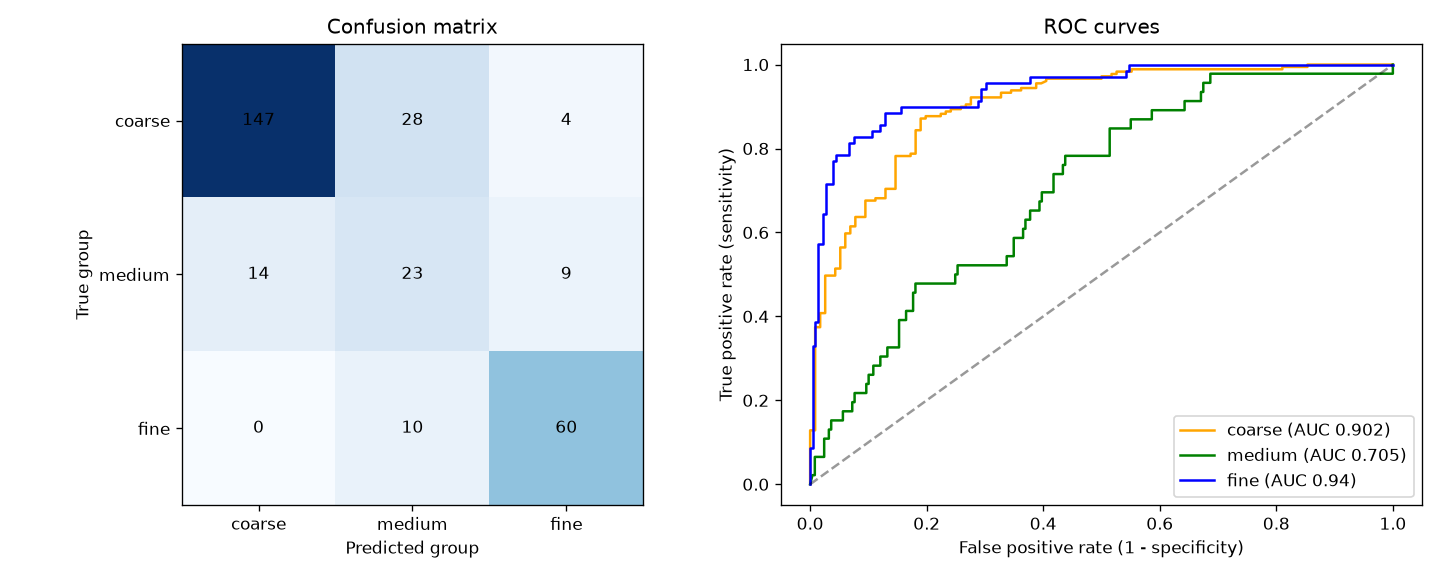

In [13]:
Image(filename=os.path.join(figures, "confusion_and_roc.png"))

### Which domain of features is important? 30 splits by site

In [14]:
repeat = pd.read_csv(os.path.join(tables, "repeated_splits.csv"))
summary = repeat.groupby("feature set")[["accuracy", "macro F1", "majority baseline"]].agg(["mean", "std"])
summary = summary.loc[["retention level", "curve shape", "van Genuchten parameters", "all features"]]
summary.round(3)

accuracy        macro F1        majority baseline  \
                             mean    std     mean    std              mean   
feature set                                                                  
retention level             0.684  0.036    0.613  0.031             0.564   
curve shape                 0.579  0.038    0.522  0.039             0.564   
van Genuchten parameters    0.700  0.040    0.671  0.036             0.564   
all features                0.753  0.031    0.705  0.031             0.564   

                                 
                            std  
feature set                      
retention level           0.042  
curve shape               0.042  
van Genuchten parameters  0.042  
all features              0.042

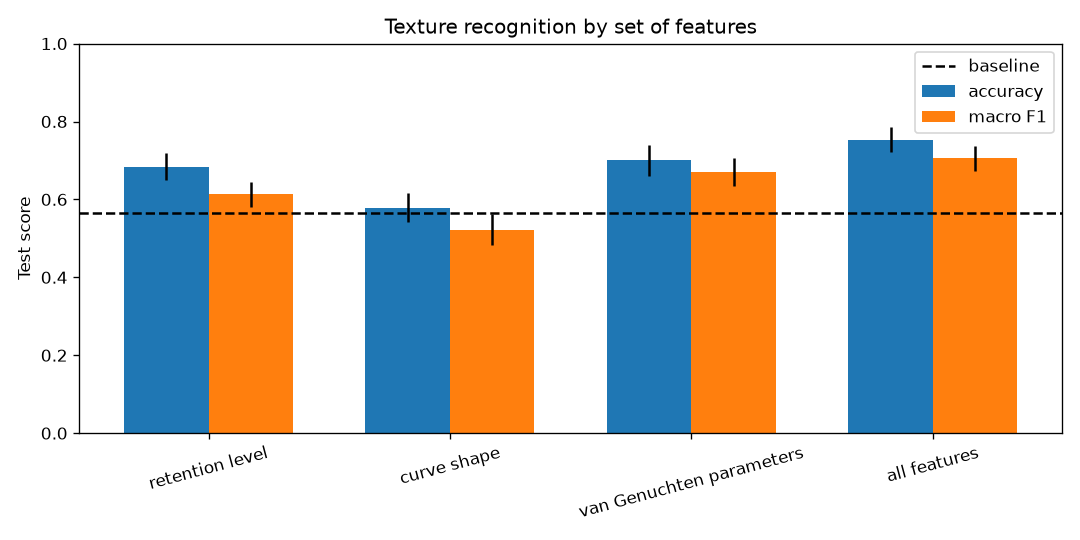

In [15]:
Image(filename=os.path.join(figures, "feature_set_comparison.png"))

With 30 splits and all the features, the accuracy is 0.753 and the macro F1 is 0.705. The van Genuchten parameters give 0.700, the retention level 0.684 and the shape 0.579, which is close to the majority baseline (0.564). The standard deviation is about 0.03 to 0.04, so I do not read small differences between the sets. No set separates the three groups well, so the texture should be an input of the future model and not something to predict.

## Matrix operations

variance explained by the first eigenvalue: 0.912


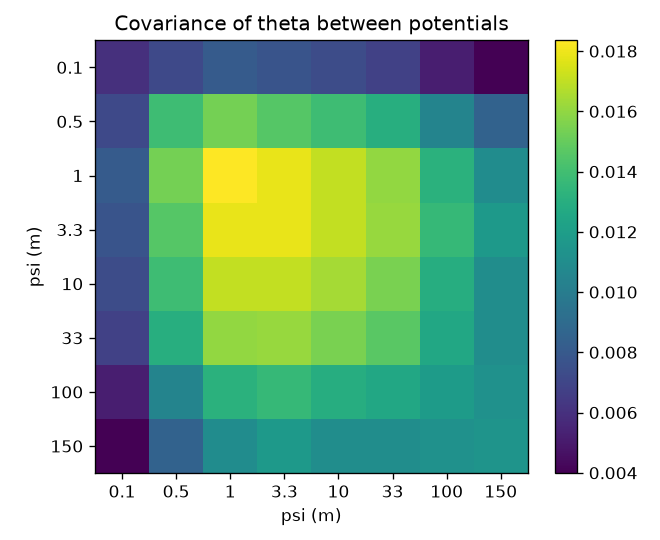

In [16]:
eigen = pd.read_csv(os.path.join(tables, "covariance_eigenvalues.csv"), index_col=0)
print("variance explained by the first eigenvalue:", round(eigen["share"].iloc[0], 3))
Image(filename=os.path.join(figures, "covariance.png"))

For 40 curves interpolated at 8 potentials, the first eigenvalue of the covariance matrix explains 91 % of the variance. Most of the difference between curves is one direction: how much water the soil holds.

## Computational cost

The notebooks `src/*/complexity_analysis.ipynb` have the analysis. The main results:

* The fit of the van Genuchten model takes almost all the time of the extraction of features.
* `roc_points` goes from O(N^2) to O(N log N) with one sort, and the speed-up grows with N.
* `build_curve_data` goes from O(C R) to O(R) with one groupby.
* The integrator is built only once in the optimized extractor, but this changes very little the total time because the fit is the expensive part.

## Discussion

The water content at high suction is the most useful feature to recognize the texture, and the shape features are the weakest. The medium group is difficult to separate from coarse and fine.

Limitations: (1) the three groups are my own grouping of the 12 USDA classes; (2) texture and source are related, since one reference gives most of the curves of each group, so a part of the separability can come from the source and not from the soil; (3) the filter `data_flag == "good quality estimate"` changes the mix of classes; (4) each curve has about ten points; (5) theta_r is not stable: 152 of the 940 fits end in its lower bound of zero; (6) the p-values are optimistic because the curves of one site are not independent; (7) the classifier is simple on purpose; (8) there is no signal of the sensor yet.

## Conclusions

I organized the code of Labs 1 and 2 as a project with three modules, a script that gives all the tables and figures, simple tests and documentation in each folder. The results of Lab 2 are the same (accuracy 0.78, macro F1 0.711, macro AUC 0.849 and 0.753 with 30 splits). The analysis of complexity showed that the main cost is the fit of the van Genuchten model, and that the ROC curve and the selection of the curves have a version with a lower order of growth. For my thesis, the main lesson is that the texture should be an input of the model and that the data source needs to be controlled when I have the real data.

## References

* Gupta, S., Papritz, A., Lehmann, P., Hengl, T., Bonetti, S., & Or, D. (2022). Global Soil Hydraulic Properties dataset based on legacy site and field data. Scientific Data, 9, 444.
* Knuth, D. E. (1976). Big Omicron and big Omega and big Theta. ACM SIGACT News, 8(2), 18-24.
* Marusteri, M., & Bacarea, V. (2010). Comparing groups for statistical differences: how to choose the right statistical test? Biochemia Medica, 20(1), 15-32.
* van Genuchten, M. Th. (1980). A closed-form equation for predicting the hydraulic conductivity of unsaturated soils. Soil Science Society of America Journal, 44(5), 892-898.

## AI Use Declaration

See the AI Use Declaration in the main `README.md` of the project.